Predicting Trajectories: LSTM Model
==============

This notebook contains only the model definition and training. Data preprocessing and DataSet creation are sourced out to create_datasets.

***1. Imports***

In [4]:
# Core data processing
import pandas as pd
import numpy as np
from pathlib import Path
import sys

# Machine Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import warnings
warnings.filterwarnings('ignore')

# Create datasets module
sys.path.append("../src")
from create_datasets import create_datasets, denormalize_xy, to_latlon

print("All imports completed successfully!")

All imports completed successfully!


***2. Creating Datasets and -Loaders***

In [5]:
WORKS_ON_FULL_DATA = False

# Create datasets for a specific ship type
train_dataset, val_dataset, test_dataset = create_datasets(input_files='../data/processed', ship_type='Cargo', with_full_data=WORKS_ON_FULL_DATA)

print(f"Train dataset: {len(train_dataset)} sequences")
print(f"Val dataset: {len(val_dataset)} sequences") 
print(f"Test dataset: {len(test_dataset)} sequences")

# Create data loaders
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"\nDataLoaders created with batch_size={batch_size}")
print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

# Test one batch
sample_input, sample_target = next(iter(train_loader))
print(f"\nSample batch - Input shape: {sample_input.shape}, Target shape: {sample_target.shape}")

Discovered 1560 parquet files from 357 vessels.
Total loaded trajectories: 1560
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
  Split into 2 segments due to large gaps
Total resampled trajectories: 1560
Train dataset: 572399 sequences
Val dataset: 128407 sequences
Test dataset: 112210 sequences

DataLoaders created with batch_size=64
Train batches: 8944
Val batches: 2007
Test batches: 1754

Sample batch - Input shape: torch.Size([64, 29, 7]), Target shape: torch.Size([64, 2])


***3. LSTM Model Architecture***

In [6]:
# Some model hyperparameters
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.1

In [7]:
class LSTMPredictor(nn.Module):
    def __init__(self, input_size=7, hidden_size=128, num_layers=2, output_size=2, dropout=0.1):
        """
        Simplified LSTM model to reduce overfitting
        """
        super(LSTMPredictor, self).__init__()
        
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        # Smaller LSTM layer
        self.lstm = nn.LSTM(input_size, 
                            hidden_size, 
                            num_layers, 
                            batch_first=True, 
                            dropout=dropout if num_layers > 1 else 0.0,)
        
        # Single output layer
        self.fc = nn.Linear(hidden_size, output_size)
        
        # Add dropout for regularization
        self.dropout = nn.Dropout(dropout)
            
    def forward(self, x, hidden=None):
        # LSTM forward pass
        lstm_out, hidden = self.lstm(x, hidden)
        
        # Apply dropout
        lstm_out = self.dropout(lstm_out)

        # Use only the last output for prediction
        last_hidden = lstm_out[:, -1, :]  #(batch, hidden_size)
        
        # Output layer
        output = self.fc(last_hidden)
        
        return output, hidden

# Create model instance
print("=== CREATING LSTM MODEL ===")

# Determine input size from sample data
sample_input, sample_target = next(iter(train_loader))
input_size = sample_input.shape[-1]  # Should be 4 (Lat, Lon, SOG, COG)
output_size = sample_target.shape[-1]  # Should be 2 (Lat, Lon)

model = LSTMPredictor(
    input_size=input_size,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    output_size=output_size,
    dropout=DROPOUT
)

print(f"Model created with:")
print(f"  Input size: {input_size}")
print(f"  Hidden size: {HIDDEN_SIZE}")
print(f"  Layers: {NUM_LAYERS}")
print(f"  Output size: {output_size}")

# Test model with sample input
print("sample_input dtype:", sample_input.dtype)
with torch.no_grad():
    sample_output, _ = model(sample_input)
    print(f"Sample input shape: {sample_input.shape}")
    print(f"Sample output shape: {sample_output.shape}")

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

=== CREATING LSTM MODEL ===
Model created with:
  Input size: 7
  Hidden size: 128
  Layers: 2
  Output size: 2
sample_input dtype: torch.float32
Sample input shape: torch.Size([64, 29, 7])
Sample output shape: torch.Size([64, 2])

Total parameters: 202,498
Trainable parameters: 202,498


***4. Training Setup***

In [8]:
# Setup loss function and optimizer
print("=== TRAINING SETUP ===")

# Mean Squared Error loss for regression
criterion = nn.MSELoss()

# Adam optimizer with learning rate
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)

# Training parameters
num_epochs = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Move model to device
model = model.to(device)
print(f"Model moved to: {device}")

print(f"\nTraining configuration:")
print(f"Loss function: MSE Loss")
print(f"Optimizer: Adam (lr=0.001)")
print(f"Scheduler: ReduceLROnPlateau")
print(f"Epochs: {num_epochs}")
print(f"Device: {device}")

=== TRAINING SETUP ===
Model moved to: cpu

Training configuration:
Loss function: MSE Loss
Optimizer: Adam (lr=0.001)
Scheduler: ReduceLROnPlateau
Epochs: 50
Device: cpu


***5. Utilities to Store/Load Model parameters***

In [9]:
# Save the trained model
def save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath):
    """
    Save model weights, optimizer state, and training history
    """
    torch.save({
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_losses': train_losses,
        'val_losses': val_losses,
        'epoch': len(train_losses)
    }, filepath)
    print(f"Model saved to {filepath}")



# Load the saved model
def load_model_and_training_state(filepath):
    """
    Load model weights, optimizer state, and training history
    """
    checkpoint = torch.load(filepath)
    
    model = LSTMPredictor(input_size=input_size, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, output_size=output_size)
    model.load_state_dict(checkpoint['model_state_dict'])
    
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    
    return model, optimizer, checkpoint['train_losses'], checkpoint['val_losses'], checkpoint['epoch']


***6. Training Loop***

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs):
    """
    Training loop with validation
    """
    print("=== STARTING TRAINING ===")
    
    train_losses = []
    val_losses = []
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)
            
            # Zero gradients
            optimizer.zero_grad()
            
            # Forward pass
            outputs, _ = model(inputs)
            loss = criterion(outputs, targets)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs, _ = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item()
        
        # Average losses
        train_loss /= len(train_loader)
        val_loss /= len(val_loader)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        
        # Update learning rate
        scheduler.step(val_loss)
        
        # Print progress
        if (epoch + 1) % 5 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f'Epoch [{epoch+1:02d}/{num_epochs}] | '
                  f'Train Loss: {train_loss:.6f} | '
                  f'Val Loss: {val_loss:.6f} | '
                  f'LR: {current_lr:.6f}')
    
    print("Training completed!")

    # Save after training
    save_model_and_training_state(model, optimizer, train_losses, val_losses, filepath='lstm_model.pth')

    print("Parameters saved after training.\n")

    return train_losses, val_losses

# Start training
train_losses, val_losses = train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs
)

***7. Visualization*** 
(Leftover from old implementation)

=== VISUALIZING RESULTS ===


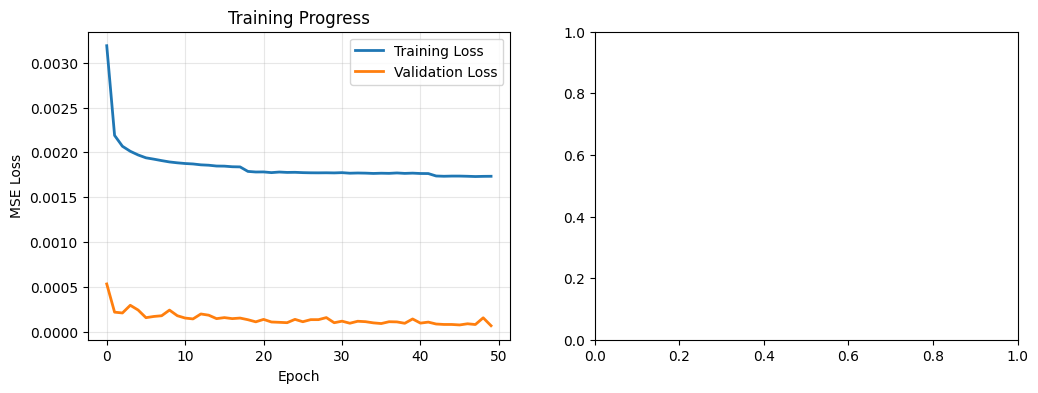

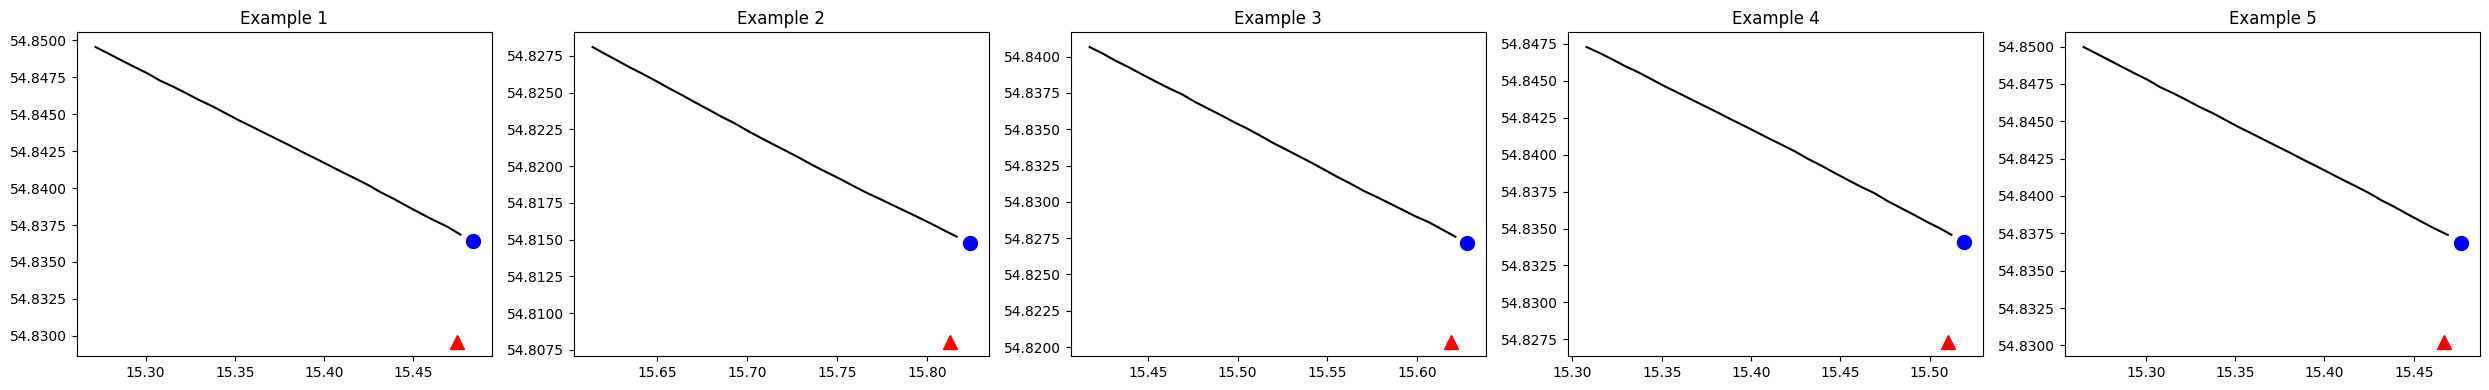


Final Metrics:
Training Loss: 0.001734
Validation Loss: 0.000068
Test Loss: 0.003018


In [10]:
def visualize_results(filepath, test_loader):
    """
    Create visualization plots for training results and predictions
    """
    print("=== VISUALIZING RESULTS ===")

    # load model from file
    model, _, train_losses, val_losses, _ = load_model_and_training_state(filepath)
    
    # Plot 1: Training and validation loss
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Training Loss', linewidth=2)
    plt.plot(val_losses, label='Validation Loss', linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.title('Training Progress')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Plot 2: Sample predictions vs actual
    plt.subplot(1, 2, 2)
    
    # Get a random batch from *test_loader*
    model.eval()
    with torch.no_grad():
        test_inputs, test_targets = next(iter(test_loader))
        test_inputs, test_targets = test_inputs.to(device), test_targets.to(device)

        # Choose a random sequence index inside the batch
        batch_size = test_inputs.shape[0]
        seq_idx = np.random.randint(0, batch_size)

        # Predict
        test_outputs, _ = model(test_inputs)

        num_examples = 5
        fig, axes = plt.subplots(1, num_examples, figsize=(5*num_examples, 4))

        for k in range(num_examples):
            seq_idx = np.random.randint(0, batch_size)
            ax = axes[k]

            trajectory = test_inputs[seq_idx].cpu().numpy()[:, :2]
            actual = test_targets[seq_idx].cpu().numpy()
            predicted = test_outputs[seq_idx].cpu().numpy()

            # denormalize 
            trajectory = denormalize_xy(trajectory)
            actual = denormalize_xy(actual)[0]
            predicted = denormalize_xy(predicted)[0]

            # also convert back to lat/lon
            trajectory = to_latlon(trajectory)
            actual = to_latlon(actual)[0]
            predicted = to_latlon(predicted)[0]

            # plot trajectory as line
            ax.plot(trajectory[:,0], trajectory[:,1], "k-", label="Input Trajectory")
            # plot actual and predicted as thick points
            ax.plot(actual[0], actual[1], "bo", markersize=10, label="Actual")
            ax.plot(predicted[0], predicted[1], "r^", markersize=10, label="Predicted")
            ax.set_title(f"Example {k+1}")

        plt.tight_layout()
        plt.show()
    
    # Print final metrics
    final_train_loss = train_losses[-1]
    final_val_loss = val_losses[-1]
    print(f"\nFinal Metrics:")
    print(f"Training Loss: {final_train_loss:.6f}")
    print(f"Validation Loss: {final_val_loss:.6f}")
    
    # Calculate test loss
    test_loss = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs, _ = model(inputs)
            loss = criterion(outputs, targets)
            test_loss += loss.item()
    
    test_loss /= len(test_loader)
    print(f"Test Loss: {test_loss:.6f}")

# Generate visualizations with denormalization
path_to_model = 'lstm_model.pth'
visualize_results(path_to_model, test_loader)

=== VISUALIZING RESULTS ===


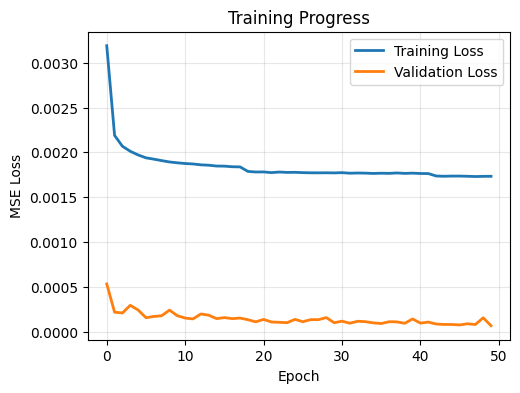

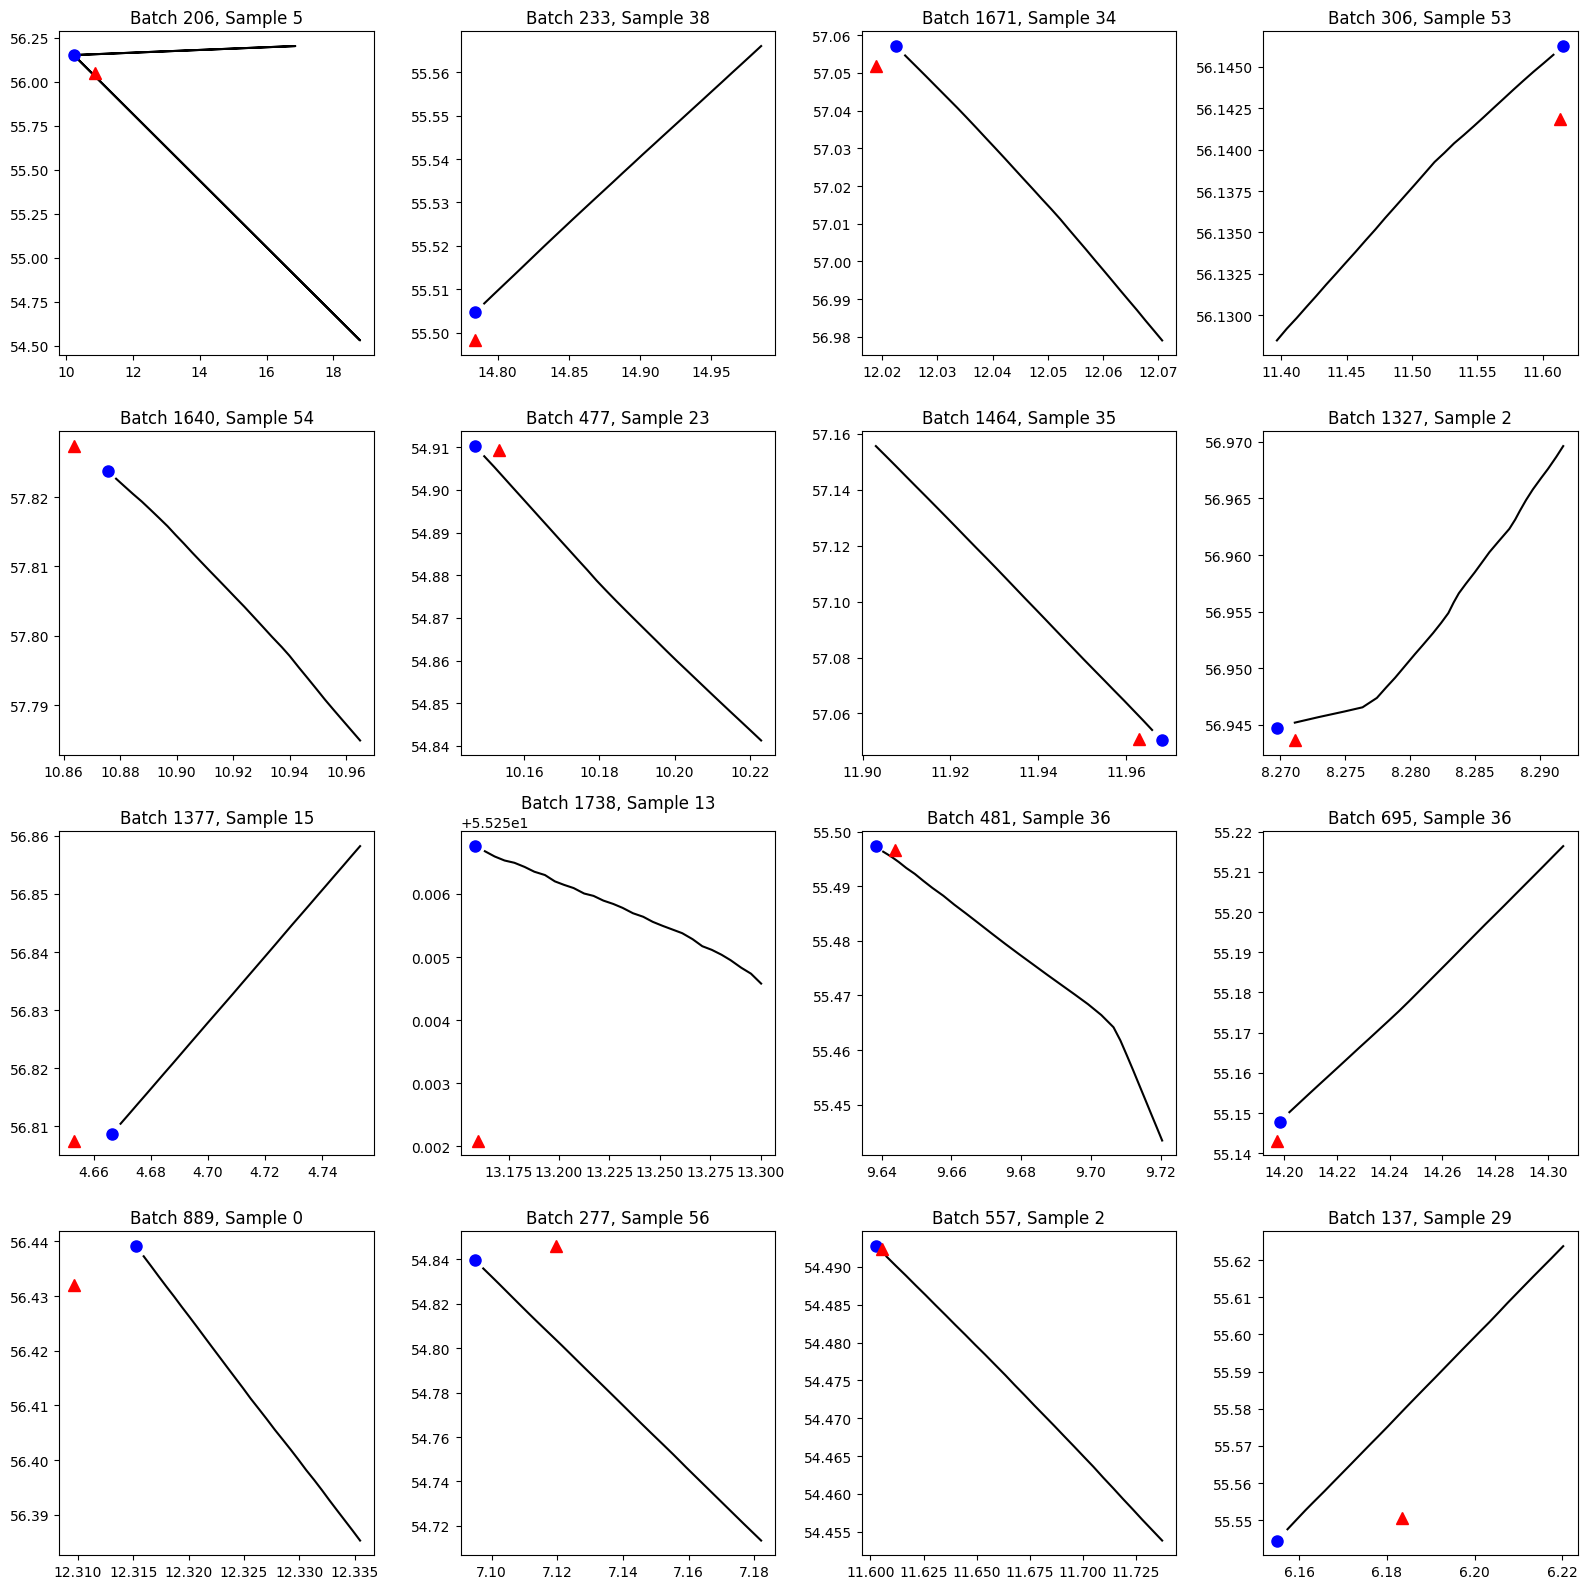

Final Metrics:
Training Loss: 0.001734
Validation Loss: 0.000068
Test Loss: 0.003018


In [11]:
def visualize_results(filepath, test_loader):
    """
    Create visualization plots for training results and predictions
    """
    print("=== VISUALIZING RESULTS ===")

    # Load model & state
    model, _, train_losses, val_losses, _ = load_model_and_training_state(filepath)
    model.eval()

    # ======== Plot 1: Training + Validation Loss ========
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Training Loss', linewidth=2)
    plt.plot(val_losses, label='Validation Loss', linewidth=2)
    plt.xlabel('Epoch')
    plt.ylabel('MSE Loss')
    plt.title('Training Progress')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # ======== Plot 2: Pick 16 different batches ========
    all_batches = list(test_loader)
    num_examples = 16

    # pick 16 distinct random batch indices
    batch_idxs = np.random.choice(len(all_batches), num_examples, replace=True)

    fig, axes = plt.subplots(4, 4, figsize=(16, 16))
    axes = axes.flatten()

    model.eval()
    with torch.no_grad():
        for k, batch_idx in enumerate(batch_idxs):
            ax = axes[k]

            # load that batch
            test_inputs, test_targets = all_batches[batch_idx]
            test_inputs = test_inputs.to(device)
            test_targets = test_targets.to(device)

            # run prediction for that entire batch
            test_outputs, _ = model(test_inputs)

            # choose 1 random item inside that batch
            bsize = test_inputs.shape[0]
            seq_idx = np.random.randint(0, bsize)

            trajectory = test_inputs[seq_idx].cpu().numpy()[:, :2]
            actual = test_targets[seq_idx].cpu().numpy()
            predicted = test_outputs[seq_idx].cpu().numpy()

            # denormalize and convert to lat/lon
            trajectory = to_latlon(denormalize_xy(trajectory))
            actual = to_latlon(denormalize_xy(actual)[0])[0]
            predicted = to_latlon(denormalize_xy(predicted)[0])[0]

            # plot
            ax.plot(trajectory[:,0], trajectory[:,1], "k-", label="Input")
            ax.plot(actual[0], actual[1], "bo", markersize=8, label="Actual")
            ax.plot(predicted[0], predicted[1], "r^", markersize=8, label="Predicted")

            ax.set_title(f"Batch {batch_idx}, Sample {seq_idx}")

    plt.tight_layout()
    plt.show()


    # ====== Print metrics ======
    print(f"Final Metrics:")
    print(f"Training Loss: {train_losses[-1]:.6f}")
    print(f"Validation Loss: {val_losses[-1]:.6f}")

    # Test loss
    test_loss = 0.0
    criterion = torch.nn.MSELoss()
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs, _ = model(inputs)
            loss = criterion(outputs, targets)
            test_loss += loss.item()

    test_loss /= len(test_loader)
    print(f"Test Loss: {test_loss:.6f}")

# Generate visualizations with denormalization
path_to_model = 'lstm_model.pth'
visualize_results(path_to_model, test_loader)

In [46]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

path_to_model = "lstm_model.pth"

model, optimizer, train_losses, val_losses, last_epoch = load_model_and_training_state(path_to_model)
model = model.to(device)
model.eval()

print(f"Loaded LSTM from {path_to_model}, last epoch = {last_epoch}")
print(f"Final train loss = {train_losses[-1]:.6f}, val loss = {val_losses[-1]:.6f}")


Device: cpu
Loaded LSTM from lstm_model.pth, last epoch = 50
Final train loss = 0.001734, val loss = 0.000068


In [47]:
from create_datasets import denormalize_xy, to_latlon  # should already be imported

all_errors = []
all_speeds_knots = []
all_lon = []
all_lat = []

model.eval()
TIME_STEP = 60.0              # seconds between samples in your sequences
KNOTS_PER_MPS = 1.0 / 0.514444  # m/s -> knots

with torch.no_grad():
    for batch_inputs, batch_targets in test_loader:
        # shapes: inputs (B, 29, 7), targets (B, 2)
        batch_inputs  = batch_inputs.to(device)
        batch_targets = batch_targets.to(device)

        # predict normalized X,Y
        batch_outputs, _ = model(batch_inputs)

        # move to numpy
        inputs_np  = batch_inputs.cpu().numpy()
        targets_np = batch_targets.cpu().numpy()
        outputs_np = batch_outputs.cpu().numpy()

        B = inputs_np.shape[0]

        # ---- denormalize true & predicted XY ----
        true_xy_den = denormalize_xy(targets_np)   # (B,2)
        pred_xy_den = denormalize_xy(outputs_np)   # (B,2)

        # ---- error in meters ----
        err = np.linalg.norm(true_xy_den - pred_xy_den, axis=1)  # (B,)
        all_errors.extend(err.tolist())

        # ---- speed estimate from last two points of input ----
        last2_xy_norm = inputs_np[:, -2:, :2].reshape(-1, 2)    # (2B,2)
        last2_xy_den  = denormalize_xy(last2_xy_norm)           # (2B,2)
        last2_xy_den  = last2_xy_den.reshape(B, 2, 2)           # (B,2,2)

        dxdy = last2_xy_den[:, 1, :] - last2_xy_den[:, 0, :]
        dist = np.linalg.norm(dxdy, axis=1)      # meters in 60 seconds
        speed_mps = dist / TIME_STEP
        speed_knots = speed_mps * KNOTS_PER_MPS
        all_speeds_knots.extend(speed_knots.tolist())

        # ---- true target position in lat/lon for maps ----
        ll = to_latlon(true_xy_den)  # (B,2): lon, lat
        all_lon.extend(ll[:, 0].tolist())
        all_lat.extend(ll[:, 1].tolist())

len(all_errors), len(all_speeds_knots), len(all_lon)


(112210, 112210, 112210)

In [ ]:

df_err = pd.DataFrame({
    "error":       all_errors,        # prediction error in meters
    "speed_knots": all_speeds_knots,  # estimated speed in knots
    "lon":         all_lon,           # longitude of target point
    "lat":         all_lat            # latitude of target point
})

# Clean up crazy outliers / NaNs if any
df_err = df_err.replace([np.inf, -np.inf], np.nan).dropna()
df_err = df_err[df_err["error"] < 1e6]   # this is OK only for visualization but it removes the point where we there might be anomalies

print(df_err.head())
print("Number of points in df_err:", len(df_err))  


        error  speed_knots        lon        lat
0  941.533712    15.661804  15.476559  54.836856
1  942.460091    15.244470  15.483616  54.836411
2  951.735369    14.358787  15.491010  54.835947
3  959.294334    15.043294  15.498511  54.835455
4  941.849044    15.272107  15.505399  54.835040
Number of points in df_err: 112206


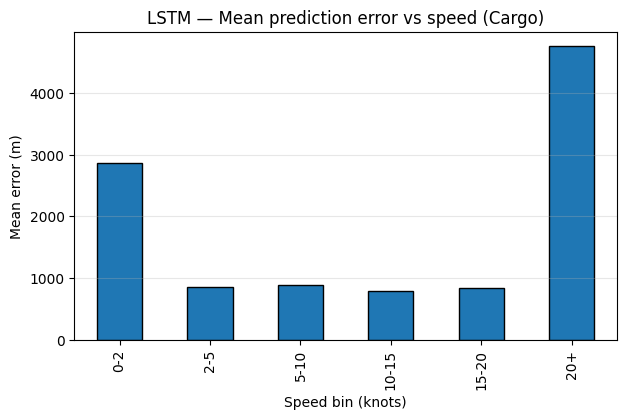

Counts per speed bin:
speed_bin
0-2       8341
2-5       2276
5-10     37725
10-15    49875
15-20    12552
20+       1294
Name: count, dtype: int64


In [49]:
errors = np.array(all_errors)
speeds = np.array(all_speeds_knots)

bins = [0, 2, 5, 10, 15, 20, 100]  # knots
labels = ["0-2", "2-5", "5-10", "10-15", "15-20", "20+"]

speed_bin = pd.cut(speeds, bins=bins, labels=labels, include_lowest=True)

df_speed_err = pd.DataFrame({
    "speed_bin": speed_bin,
    "error": errors
}).dropna()

mean_err_by_bin = df_speed_err.groupby("speed_bin")["error"].mean()
count_by_bin    = df_speed_err["speed_bin"].value_counts().sort_index()

plt.figure(figsize=(7,4))
mean_err_by_bin.plot(kind="bar", edgecolor="k")
plt.ylabel("Mean error (m)")
plt.xlabel("Speed bin (knots)")
plt.title("LSTM — Mean prediction error vs speed (Cargo)")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Counts per speed bin:")
print(count_by_bin)


Error for this example: 1055.3 m


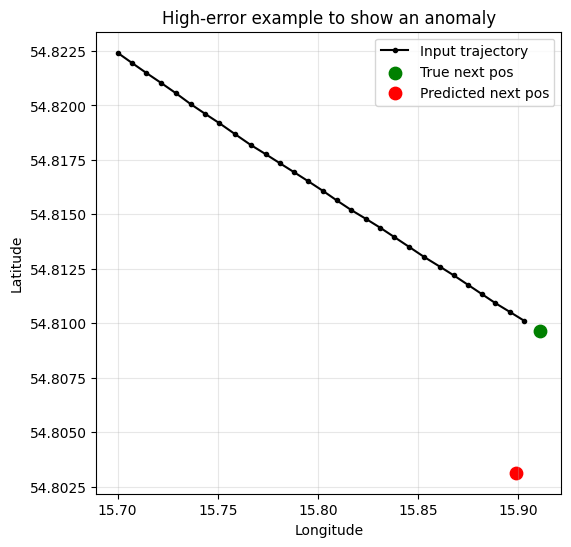

In [51]:
def plot_one_high_error_example():
    batch_inputs, batch_targets = next(iter(test_loader))
    batch_inputs  = batch_inputs.to(device)
    batch_targets = batch_targets.to(device)

    with torch.no_grad():
        batch_outputs, _ = model(batch_inputs)

    inputs_np  = batch_inputs.cpu().numpy()
    targets_np = batch_targets.cpu().numpy()
    outputs_np = batch_outputs.cpu().numpy()

    # compute batch errors (in meters)
    true_xy_den = denormalize_xy(targets_np)
    pred_xy_den = denormalize_xy(outputs_np)
    errs_batch = np.linalg.norm(true_xy_den - pred_xy_den, axis=1)

    j = np.argmax(errs_batch)  # worst example in this batch

    traj_xy   = denormalize_xy(inputs_np[j, :, :2])   # (29,2)
    true_xy   = true_xy_den[j]
    pred_xy   = pred_xy_den[j]

    traj_ll = to_latlon(traj_xy)
    true_ll = to_latlon(true_xy)[0]
    pred_ll = to_latlon(pred_xy)[0]

    print(f"Error for this example: {errs_batch[j]:.1f} m")

    plt.figure(figsize=(6,6))
    plt.plot(traj_ll[:,0], traj_ll[:,1], "k-o", ms=3, label="Input trajectory")
    plt.scatter(true_ll[0], true_ll[1], c="green", s=80, label="True next pos")
    plt.scatter(pred_ll[0], pred_ll[1], c="red",   s=80, label="Predicted next pos")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("High-error example to show an anomaly")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_one_high_error_example()


In [42]:
def in_box(df, north, west, south, east):
    """Return boolean mask for points inside a lon/lat rectangle."""
    return (
        (df["lat"] <= north) &
        (df["lat"] >= south) &
        (df["lon"] >= west) &
        (df["lon"] <= east)
    )

def in_open_sea(df):
    """
    Rough 'open sea' west of Denmark (North Sea / Skagerrak).
    Tweak numbers if you want to move the cyan box.
    """
    return in_box(
        df,
        north=59.5,   # top
        south=54.5,   # bottom
        west=3.5,     # left (more towards open ocean)
        east=8.5      # right (before Jutland coast)
    )

def in_strait(df):
    """
    Narrow strait around Storebælt / Øresund.
    These bounds correspond roughly to your magenta box.
    """
    return in_box(
        df,
        north=56.9,   # top
        south=54.8,   # bottom
        west=9.5,     # left
        east=12.5     # right
    )


In [43]:
import plotly.express as px
import plotly.graph_objects as go

# To avoid lag, randomly sample up to 50k points
if len(df_err) > 50000:
    df_plot = df_err.sample(n=50000, random_state=0)
else:
    df_plot = df_err.copy()

df_plot["error_vis"] = df_plot["error"].clip(upper=np.percentile(df_plot["error"], 95))
# Base scatter on map: points colored by error
fig = px.scatter_mapbox(
    df_plot,
    lat="lat",
    lon="lon",
    color="error_vis",
    color_continuous_scale="Inferno",
    zoom=5.5,                          
    height=750,
    opacity=0.5,
    mapbox_style="open-street-map",
    center=dict(lat=56.0, lon=11.0)    # center on Denmark
)
# Function to draw a rectangular region as a polygon
def add_region_box(fig, box, name, color):
    lats_box = [
        box["lat_min"],
        box["lat_min"],
        box["lat_max"],
        box["lat_max"],
        box["lat_min"],
    ]
    lons_box = [
        box["lon_min"],
        box["lon_max"],
        box["lon_max"],
        box["lon_min"],
        box["lon_min"],
    ]

    # outline
    fig.add_trace(go.Scattermapbox(
        lat=lats_box,
        lon=lons_box,
        mode="lines",
        line=dict(width=3, color=color),
        name=name.replace("_", " ").title(),
    ))

    # label in the middle
    center_lat = 0.5 * (box["lat_min"] + box["lat_max"])
    center_lon = 0.5 * (box["lon_min"] + box["lon_max"])

    fig.add_trace(go.Scattermapbox(
        lat=[center_lat],
        lon=[center_lon],
        mode="markers+text",
        text=[name.replace("_", " ").title()],
        textposition="top center",
        marker=dict(size=8, color=color),
        showlegend=False,
    ))

# Add the two boxes
add_region_box(fig, REGIONS["open_sea"], "open_sea", "cyan")
add_region_box(fig, REGIONS["narrow_strait"], "narrow_strait", "magenta")

fig.update_layout(
    title=(
        "LSTM prediction error around Denmark<br>"
        "<sub>Colored points = error (m). Cyan box = 'open sea', "
        "Magenta box = 'narrow strait'.</sub>"
    ),
)

fig.show()



In [45]:
mask_open   = in_open_sea(df_plot)
mask_strait = in_strait(df_plot)

print("Open sea points:",   mask_open.sum())
print("Strait points:",     mask_strait.sum())

print("\nOpen sea:")
print("  mean error (m):  ", df_plot.loc[mask_open, "error"].mean())
print("  median error (m):", df_plot.loc[mask_open, "error"].median())

print("\nNarrow strait:")
print("  mean error (m):  ", df_plot.loc[mask_strait, "error"].mean())
print("  median error (m):", df_plot.loc[mask_strait, "error"].median())


Open sea points: 9056
Strait points: 8185

Open sea:
  mean error (m):   989.8490452295453
  median error (m): 737.7306744582853

Narrow strait:
  mean error (m):   985.2860950896114
  median error (m): 459.78410194959434
